In [8]:
# Import libraries for the digits dataset, SVM, evaluation, and plotting.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split 
from sklearn import datasets
from sklearn import svm
from sklearn import metrics

In [9]:
# Load the built-in handwritten digits dataset.
digits = datasets.load_digits()

In [10]:
# Separate image pixel features and digit labels.
# Each 8×8 image is flattened into 64 pixel values used as input features.
X = digits.data
# These are the correct digit labels, from 0 to 9.
y = digits.target

In [11]:
# Split the dataset into training and testing sets.
# Use 33% of the records for testing and the rest for training.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [13]:
# Create a Support Vector Machine classifier with a linear kernel.
# SVC is a Support Vector Machine classifier; the linear kernel creates linear decision boundaries.
clf = svm.SVC(kernel='linear')

In [14]:
# Train the classifier using the training dataset.
# Train the classifier by learning from examples with known digit labels.
clf.fit(X_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [15]:
# Predict digit labels for the test images.
# Predict the digit label for each unseen test image.
y_pred = clf.predict(X_test)

In [19]:
# Calculate classification accuracy.
# Accuracy is the fraction of test predictions that are correct.
accuracy = metrics.accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9797979797979798


In [20]:
# Generate the confusion matrix.
# Rows represent actual classes and columns represent predicted classes.
cm = metrics.confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[55  0  0  0  0  0  0  0  0  0]
 [ 0 53  0  0  1  0  0  0  1  0]
 [ 0  0 52  0  0  0  0  0  0  0]
 [ 0  0  0 54  0  1  0  0  1  0]
 [ 0  0  0  0 64  0  0  0  0  0]
 [ 0  0  0  0  0 71  0  1  0  1]
 [ 0  0  0  0  0  0 57  0  0  0]
 [ 0  0  0  0  0  0  0 61  0  1]
 [ 0  1  0  1  0  1  0  0 49  0]
 [ 0  0  0  0  1  0  0  0  1 66]]


In [21]:
# Display precision, recall, and F1-score for each digit.
print("Classification Report:")
# The report includes precision, recall, F1-score, and support for each class.
print(metrics.classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        55
           1       0.98      0.96      0.97        55
           2       1.00      1.00      1.00        52
           3       0.98      0.96      0.97        56
           4       0.97      1.00      0.98        64
           5       0.97      0.97      0.97        73
           6       1.00      1.00      1.00        57
           7       0.98      0.98      0.98        62
           8       0.94      0.94      0.94        52
           9       0.97      0.97      0.97        68

    accuracy                           0.98       594
   macro avg       0.98      0.98      0.98       594
weighted avg       0.98      0.98      0.98       594



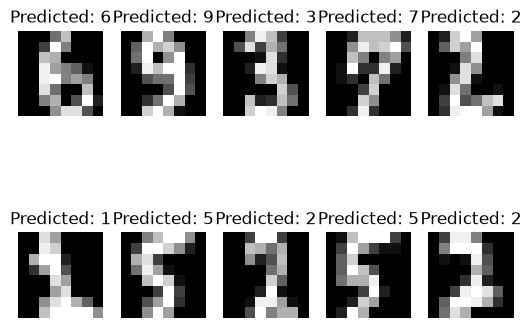

In [32]:
# Visualize the first ten test images and their predicted labels.
for i in range(10):
    # Place each image in a display grid containing two rows and five columns.
    plt.subplot(2, 5, i + 1)
    # Convert the 64 pixel values back into the original 8×8 image shape.
    plt.imshow(X_test[i].reshape(8, 8), cmap='gray')
    plt.title(f"Predicted: {y_pred[i]}")
    plt.axis('off')

plt.show()